# 02 · Exploratory data analysis and statistics

**Scope: the train period only (2024-07-01 → 2025-06-30).** What we learn here will shape
feature design and modelling decisions. If we also looked at the validation, test or
production periods, those decisions would be informed by data the model is later evaluated
on: a quiet form of leakage called *data snooping*. Later periods appear only as row counts.

**Labels:** the observed labels in `core.fraud_labels` (eventually reported fraud), not the
simulator's ground truth. Labels of the train period are mature (the label window is 120
days and the extract ends a year later), so a retrospective view is fair here. It would not
be fair for recent months: see section 2.

**Reading the numbers:** with 1.3M rows nearly every difference is statistically
significant. Effect sizes (lift, Cramér's V, univariate AUC) and 95% intervals matter more
than p-values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from fraudplatform.config import load_splits
from fraudplatform.db import connect
from fraudplatform.eda import plots, stats
from fraudplatform.eda.data import load_transactions, split_sizes

plots.apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

splits = load_splits()
with connect() as conn:
    sizes = split_sizes(conn, splits)
    df = load_transactions(conn, splits.train.start, splits.train.end)

df["local_hour"] = df["local_ts"].dt.hour
df["local_weekday"] = df["local_ts"].dt.dayofweek
df["month"] = df["ts"].dt.strftime("%Y-%m")
df["cross_border"] = np.where(
    df["txn_country"].astype(str) == df["home_country"].astype(str), "domestic", "cross-border"
)
df["operating_system"] = df["operating_system"].cat.add_categories("none").fillna("none")
sizes

,split,start,end,transactions
0,train,2024-07-01,2025-07-01,1344750
1,validation,2025-07-01,2025-10-01,359220
2,test,2025-10-01,2026-01-01,387978
3,production,2026-01-01,2026-07-01,760511


## 1. Base rate and class imbalance

The base rate is the share of transactions that are fraud. Every other number in the
project is read against it: a model that finds nothing is "right" 1 - base rate of the time.

In [2]:
n = len(df)
frauds = int(df["is_fraud"].sum())
base_rate = frauds / n
ci_low, ci_high = stats.wilson_interval(frauds, n)
days = (splits.train.end - splits.train.start).days

pd.DataFrame(
    {
        "value": [
            f"{n:,}",
            f"{frauds:,}",
            f"{base_rate:.3%} (95% CI {ci_low:.3%} – {ci_high:.3%})",
            f"{n / days:,.0f}",
            f"{frauds / days:,.1f}",
            f"1 : {(n - frauds) / frauds:,.0f}",
        ]
    },
    index=[
        "transactions",
        "labelled fraud",
        "base rate",
        "transactions per day",
        "frauds per day",
        "fraud : legit",
    ],
)

,value
transactions,"1,344,750"
labelled fraud,"11,410"
base rate,0.848% (95% CI 0.833% – 0.864%)
transactions per day,"3,684"
frauds per day,31.3
fraud : legit,1 : 117


### Why accuracy is misleading here

A "model" that approves everything never catches a fraud, yet its accuracy equals
1 - base rate. Its confusion matrix:

In [3]:
confusion = pd.DataFrame(
    [[n - frauds, 0], [frauds, 0]],
    index=["actual legit", "actual fraud"],
    columns=["predicted legit", "predicted fraud"],
)
display(confusion)
print(f"accuracy  = {(n - frauds) / n:.3%}")
print("recall    = 0.000%  (no fraud caught)")
print("precision = undefined (no alerts)")
print(f"PR-AUC of a random score ≈ base rate = {base_rate:.3%};  ROC-AUC of a random score = 0.5")

,predicted legit,predicted fraud
actual legit,1333340,0
actual fraud,11410,0


accuracy  = 99.152%
recall    = 0.000%  (no fraud caught)
precision = undefined (no alerts)
PR-AUC of a random score ≈ base rate = 0.848%;  ROC-AUC of a random score = 0.5


### The base-rate effect (Bayes' rule)

Suppose a detector catches 90% of fraud. How many of its alerts are real fraud?
`precision = recall·p / (recall·p + FPR·(1 − p))` with p = base rate. Even a 1% false positive
rate floods the alert queue, because legit transactions outnumber fraud ~117 to 1.

In [4]:
fpr_grid = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]
pd.DataFrame(
    {
        "false_positive_rate": [f"{f:.2%}" for f in fpr_grid],
        "precision_at_90pct_recall": [
            f"{stats.precision_from_rates(base_rate, 0.9, f):.1%}" for f in fpr_grid
        ],
        "alerts_per_day": [round((0.9 * frauds + f * (n - frauds)) / days) for f in fpr_grid],
        "of_which_fraud": [round(0.9 * frauds / days) for _ in fpr_grid],
    }
)

,false_positive_rate,precision_at_90pct_recall,alerts_per_day,of_which_fraud
0,0.10%,88.5%,32,28
1,0.25%,75.5%,37,28
2,0.50%,60.6%,46,28
3,1.00%,43.5%,65,28
4,2.00%,27.8%,101,28
5,5.00%,13.3%,211,28


## 2. Labels: how late do they arrive?

A label exists only once fraud is reported (chargeback, customer report or investigation).
The delay decides (a) which labels a historical feature may use at time t and (b) how long
we must wait before measuring a model in production.

In [5]:
fraud = df[df["is_fraud"]]
delay_days = (fraud["reported_at"] - fraud["ts"]).dt.total_seconds() / 86_400
within = {f"≤ {d} days": (delay_days <= d).mean() for d in (7, 14, 30, 60, 90, 120)}
display(pd.Series(within, name="share of fraud labels").map("{:.1%}".format).to_frame())
display(
    delay_days.groupby(fraud["label_source"], observed=True)
    .describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]]
    .round(1)
)
cleared = int(((~df["is_fraud"]) & df["label_source"].notna()).sum())
print(f"disputes investigated and cleared as legit: {cleared:,}")

,share of fraud labels
≤ 7 days,15.4%
≤ 14 days,42.9%
≤ 30 days,76.3%
≤ 60 days,94.4%
≤ 90 days,98.4%
≤ 120 days,100.0%


,count,50%,90%,max
label_source,,,,
chargeback,6985.0,16.5,49.5,120.0
customer_report,3232.0,16.1,47.6,120.0
investigation,1193.0,14.6,38.3,120.0


disputes investigated and cleared as legit: 420


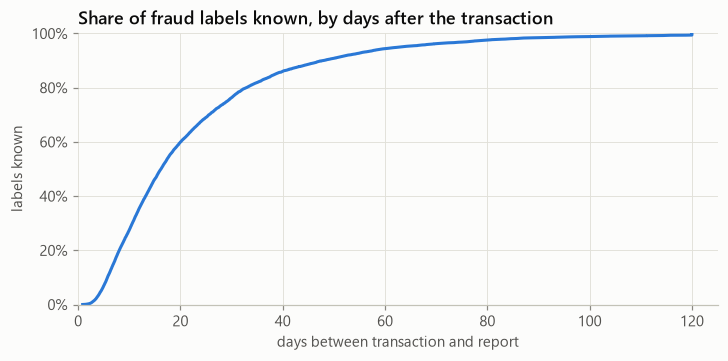

In [6]:
x = np.sort(delay_days.to_numpy())
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=plots.BLUE)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_xlim(0, 125)
ax.set_ylim(0, 1)
ax.set_title("Share of fraud labels known, by days after the transaction")
ax.set_xlabel("days between transaction and report")
ax.set_ylabel("labels known")
plots.save(fig, "label_delay_ecdf")
plt.show()

## 3. Amount: skewness, outliers and signal

In [7]:
amount = df["amount_eur"]
log_amount = np.log10(amount)
shape = pd.DataFrame(
    {
        "skewness": [stats.stats.skew(amount), stats.stats.skew(log_amount)],
        "excess_kurtosis": [stats.stats.kurtosis(amount), stats.stats.kurtosis(log_amount)],
    },
    index=["amount_eur", "log10(amount_eur)"],
).round(2)
display(amount.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).round(2).to_frame().T)
display(shape)

,count,mean,std,min,1%,25%,50%,75%,99%,99.9%,max
amount_eur,1344750.0,103.78,307.26,0.5,1.8,18.74,41.07,87.84,1144.26,3246.48,108077.37


,skewness,excess_kurtosis
amount_eur,59.79,14371.89
log10(amount_eur),0.10,0.57


Outliers by Tukey's fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR). On a skewed variable the raw-scale
rule flags a large share of perfectly normal purchases; on the log scale it flags far fewer.
Either way, the question that matters for fraud is whether the flagged rows are errors or
signal.

In [8]:
rows = []
for name, values in (("raw scale", amount), ("log10 scale", log_amount)):
    low, high = stats.tukey_fences(values)
    upper = values > high
    rows.append(
        {
            "scale": name,
            "upper_fence_eur": round(10**high if name == "log10 scale" else high, 2),
            "flagged_share": f"{upper.mean():.2%}",
            "fraud_rate_flagged": f"{df.loc[upper, 'is_fraud'].mean():.2%}",
            "fraud_rate_rest": f"{df.loc[~upper, 'is_fraud'].mean():.2%}",
        }
    )
display(pd.DataFrame(rows))
print(f"univariate AUC of amount_eur: {stats.univariate_auc(amount, df['is_fraud']):.3f}")

,scale,upper_fence_eur,flagged_share,fraud_rate_flagged,fraud_rate_rest
0,raw scale,191.49,10.63%,2.97%,0.60%
1,log10 scale,891.41,1.54%,5.03%,0.78%


univariate AUC of amount_eur: 0.703


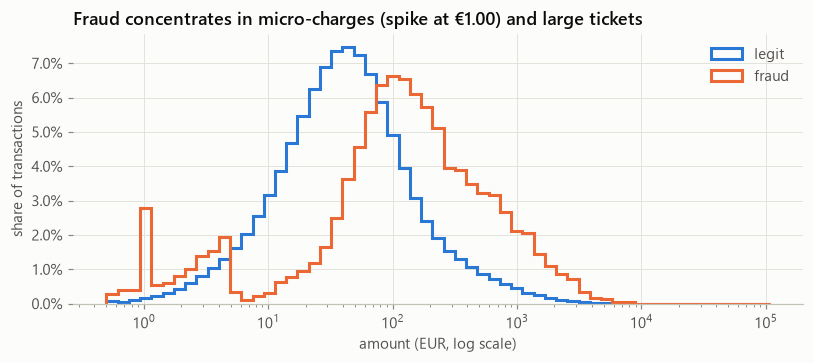

In [9]:
bins = np.logspace(np.log10(0.5), np.log10(amount.max()), 60)
fig = plots.plot_two_distributions(
    amount[~df["is_fraud"]].to_numpy(),
    amount[df["is_fraud"]].to_numpy(),
    bins,
    "Fraud concentrates in micro-charges (spike at €1.00) and large tickets",
    "amount (EUR, log scale)",
    log_x=True,
)
plots.save(fig, "amount_distribution")
plt.show()

,amount_decile,transactions,frauds,fraud_rate,ci_low,ci_high,lift,min,max
0,D1,134542,1399,0.010398,0.009870,0.010954,1.225507,0.50,8.35
1,D2,134442,142,0.001056,0.000896,0.001245,0.124483,8.36,15.18
2,D3,134446,209,0.001555,0.001358,0.001780,0.183212,15.19,22.48
3,D4,134487,236,0.001755,0.001545,0.001993,0.206818,22.49,30.87
4,D5,134554,398,0.002958,0.002682,0.003263,0.348612,30.88,41.07
5,D6,134458,610,0.004537,0.004191,0.004910,0.534686,41.08,54.43
6,D7,134412,894,0.006651,0.006231,0.007100,0.783890,54.44,73.80
7,D8,134476,1347,0.010017,0.009498,0.010563,1.180535,73.81,107.84
8,D9,134460,2140,0.015916,0.015260,0.016598,1.875757,107.85,202.71
9,D10,134473,4035,0.030006,0.029108,0.030931,3.536424,202.72,108077.37


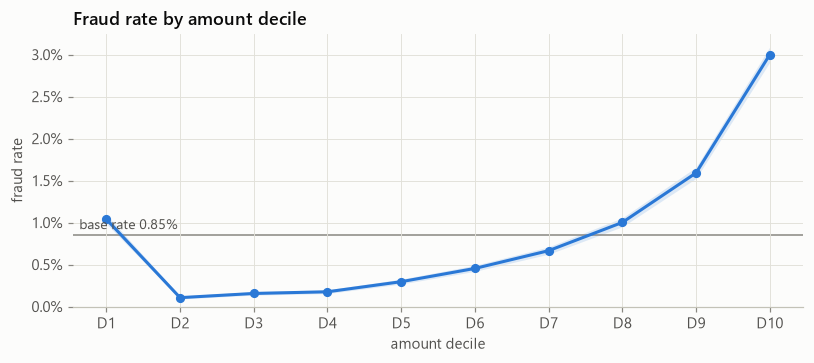

In [10]:
df["amount_decile"] = pd.qcut(amount, 10, labels=[f"D{i}" for i in range(1, 11)])
by_decile = stats.rate_table(df, "amount_decile")
edges = amount.groupby(df["amount_decile"], observed=True).agg(["min", "max"]).round(2)
display(by_decile.join(edges, on="amount_decile"))
fig = plots.plot_rate_over(
    by_decile, "amount_decile", base_rate, "Fraud rate by amount decile", "amount decile"
)
plots.save(fig, "rate_by_amount_decile")
plt.show()

## 4. Time: hour, weekday and month

Hours are LOCAL to the country where the payment happened (terminal or IP country).

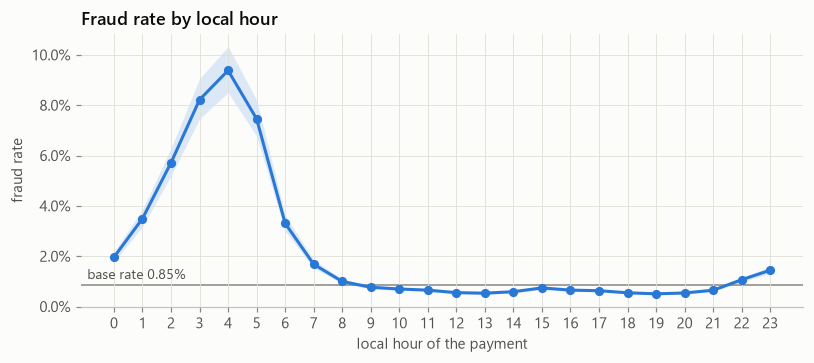

local_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
transactions,18215.0000,11184.0000,6983.0000,4551.0000,3945.0000,5123.0000,11953.0000,26198.0000,45784.0000,60858.0000,...,86114.0000,78443.0000,82204.0000,90905.0000,101667.0000,106645.0000,98211.0000,75539.0000,50979.0000,31247.0000
frauds,357.0000,391.0000,399.0000,374.0000,370.0000,382.0000,395.0000,440.0000,456.0000,466.0000,...,507.0000,580.0000,535.0000,572.0000,555.0000,538.0000,529.0000,489.0000,542.0000,451.0000
fraud_rate,0.0196,0.0350,0.0571,0.0822,0.0938,0.0746,0.0330,0.0168,0.0100,0.0077,...,0.0059,0.0074,0.0065,0.0063,0.0055,0.0050,0.0054,0.0065,0.0106,0.0144
ci_low,0.0177,0.0317,0.0519,0.0745,0.0851,0.0677,0.0300,0.0153,0.0091,0.0070,...,0.0054,0.0068,0.0060,0.0058,0.0050,0.0046,0.0049,0.0059,0.0098,0.0132
ci_high,0.0217,0.0385,0.0628,0.0905,0.1033,0.0821,0.0364,0.0184,0.0109,0.0084,...,0.0064,0.0080,0.0071,0.0068,0.0059,0.0055,0.0059,0.0071,0.0116,0.0158
lift,2.3099,4.1204,6.7342,9.6855,11.0538,8.7881,3.8947,1.9794,1.1738,0.9025,...,0.6939,0.8714,0.7670,0.7416,0.6434,0.5946,0.6348,0.7629,1.2530,1.7011


In [11]:
by_hour = stats.rate_table(df, "local_hour")
fig = plots.plot_rate_over(
    by_hour, "local_hour", base_rate, "Fraud rate by local hour", "local hour of the payment"
)
plots.save(fig, "rate_by_hour")
plt.show()
display(by_hour.set_index("local_hour").T.round(4))

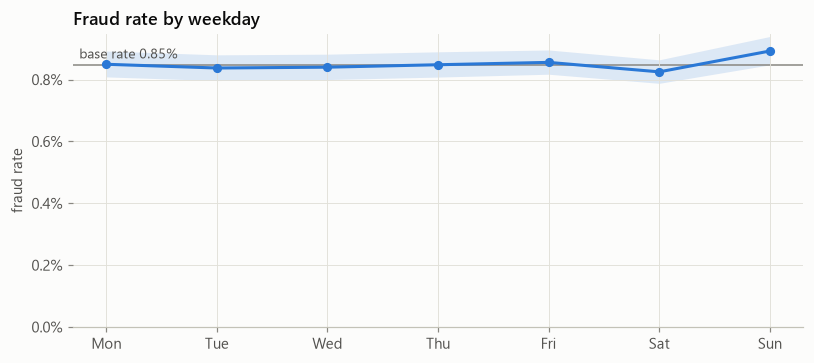

,local_weekday,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,Mon,184573,1568,0.0085,0.0081,0.0089,1.0012
1,Tue,184372,1544,0.0084,0.0080,0.0088,0.9870
2,Wed,189971,1596,0.0084,0.0080,0.0088,0.9902
3,Thu,193512,1641,0.0085,0.0081,0.0089,0.9994
4,Fri,212232,1816,0.0086,0.0082,0.0090,1.0085
5,Sat,217936,1798,0.0083,0.0079,0.0086,0.9723
6,Sun,162154,1447,0.0089,0.0085,0.0094,1.0517


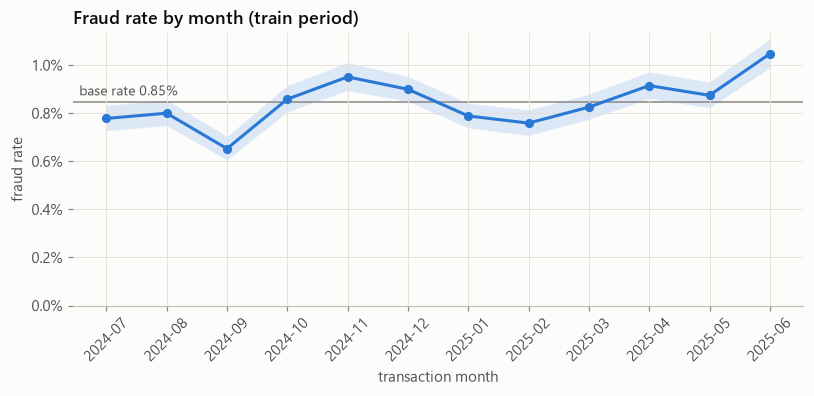

,month,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,2024-07,106655,830,0.007782,0.007272,0.008327,0.917176
1,2024-08,108985,872,0.008001,0.007489,0.008548,0.942987
2,2024-09,104950,685,0.006527,0.006057,0.007032,0.769244
3,2024-10,109722,942,0.008585,0.008056,0.009149,1.011843
4,2024-11,108308,1030,0.009510,0.008949,0.010106,1.120812
5,2024-12,127717,1149,0.008996,0.008493,0.009529,1.060296
6,2025-01,113988,899,0.007887,0.007390,0.008417,0.929515
7,2025-02,102653,779,0.007589,0.007076,0.008138,0.894379
8,2025-03,115608,954,0.008252,0.007747,0.008790,0.972560
9,2025-04,113139,1035,0.009148,0.008610,0.009720,1.078162


In [12]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = stats.rate_table(df, "local_weekday")
fig = plots.plot_rate_over(
    by_weekday, "local_weekday", base_rate, "Fraud rate by weekday", "", xticks=weekday_names
)
plots.save(fig, "rate_by_weekday")
plt.show()
display(by_weekday.assign(local_weekday=weekday_names).round(4))
by_month = stats.rate_table(df, "month")
fig = plots.plot_rate_over(
    by_month, "month", base_rate, "Fraud rate by month (train period)", "transaction month"
)
fig.axes[0].tick_params(axis="x", rotation=45)
plots.save(fig, "rate_by_month")
plt.show()
display(by_month)

## 5. Categorical attributes vs fraud

Chi-square test of independence and Cramér's V (bias-corrected, 0 = no association,
1 = perfect). p-values are Benjamini-Hochberg adjusted for testing many attributes.

In [13]:
categorical = [
    "payment_method",
    "merchant_category",
    "merchant_risk_level",
    "merchant_channel",
    "customer_segment",
    "card_type",
    "device_type",
    "operating_system",
    "txn_country",
    "home_country",
    "cross_border",
]
association = stats.association_with_target(df, categorical, "is_fraud")
association.style.format(
    {"chi2": "{:,.0f}", "p_value": "{:.1e}", "p_adjusted_bh": "{:.1e}", "cramers_v": "{:.3f}"}
)

,feature,categories,chi2,dof,p_value,cramers_v,p_adjusted_bh
0,cross_border,2,"85,819",1,0.0e+00,0.253,0.0e+00
1,operating_system,7,"43,087",6,0.0e+00,0.179,0.0e+00
2,txn_country,14,"26,792",13,0.0e+00,0.141,0.0e+00
3,merchant_category,14,"23,926",13,0.0e+00,0.133,0.0e+00
4,device_type,5,"20,350",4,0.0e+00,0.123,0.0e+00
5,merchant_risk_level,3,"8,485",2,0.0e+00,0.079,0.0e+00
6,payment_method,4,"4,177",3,0.0e+00,0.056,0.0e+00
7,merchant_channel,2,"3,205",1,0.0e+00,0.049,0.0e+00
8,card_type,4,"1,790",3,0.0e+00,0.036,0.0e+00
9,customer_segment,4,370,3,8.9e-80,0.017,9.7e-80


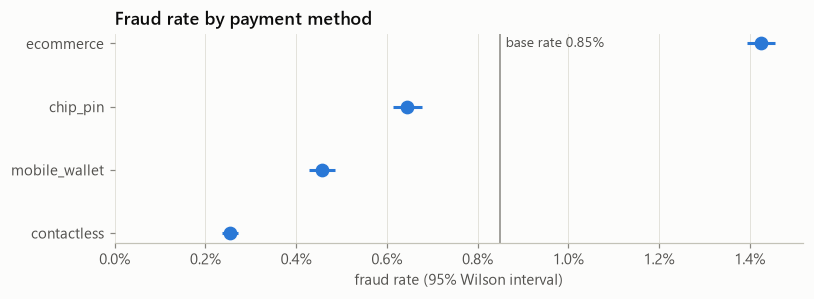

,payment_method,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,chip_pin,228607,1474,0.0064,0.0061,0.0068,0.7599
1,contactless,340167,863,0.0025,0.0024,0.0027,0.2990
2,ecommerce,570945,8138,0.0143,0.0139,0.0146,1.6799
3,mobile_wallet,205031,935,0.0046,0.0043,0.0049,0.5375


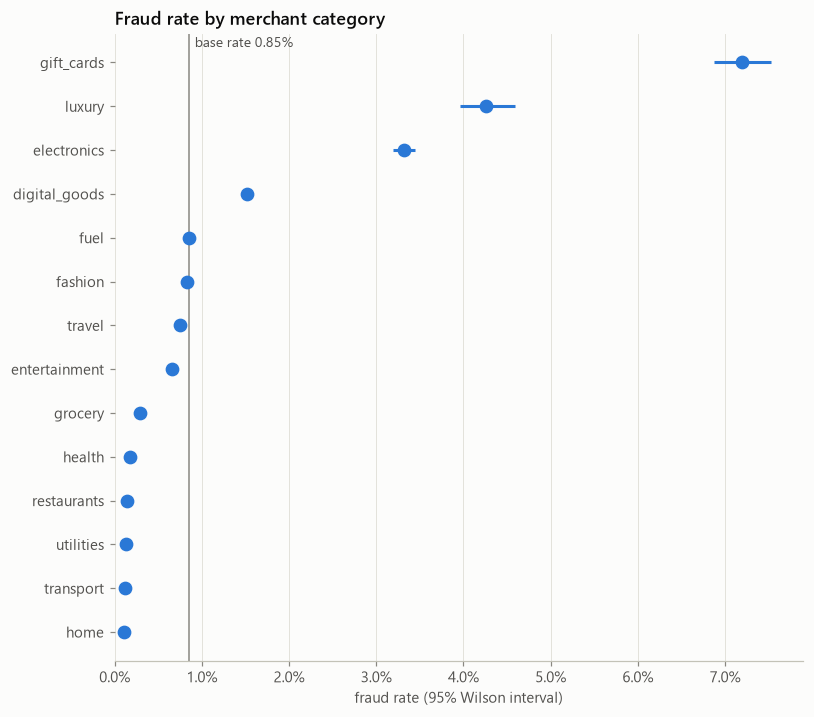

,merchant_category,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,digital_goods,148556,2262,0.0152,0.0146,0.0159,1.7946
1,electronics,75820,2513,0.0331,0.0319,0.0344,3.9063
2,entertainment,111910,732,0.0065,0.0061,0.0070,0.7709
3,fashion,124526,1027,0.0082,0.0078,0.0088,0.9720
4,fuel,68109,578,0.0085,0.0078,0.0092,1.0002
5,gift_cards,24611,1770,0.0719,0.0688,0.0752,8.4762
6,grocery,244161,708,0.0029,0.0027,0.0031,0.3418
7,health,43964,79,0.0018,0.0014,0.0022,0.2118
8,home,53721,57,0.0011,0.0008,0.0014,0.1251
9,luxury,15339,654,0.0426,0.0396,0.0459,5.0250


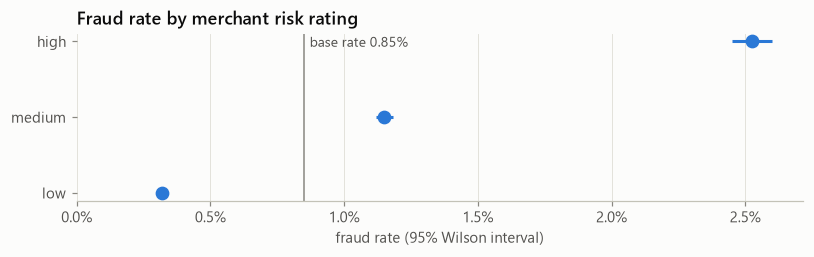

,merchant_risk_level,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,high,164898,4163,0.0252,0.0245,0.0260,2.9754
1,low,761704,2439,0.0032,0.0031,0.0033,0.3774
2,medium,418148,4808,0.0115,0.0112,0.0118,1.3552


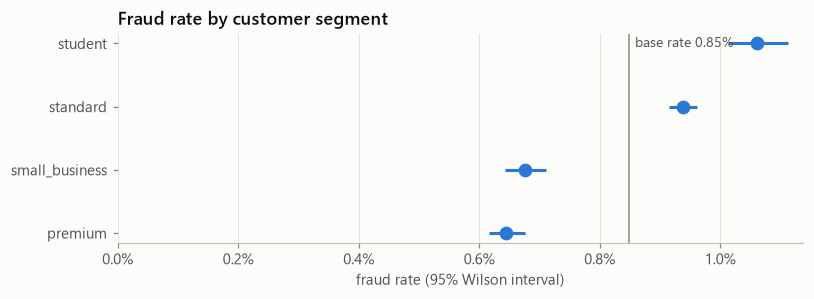

,customer_segment,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,premium,276359,1782,0.0064,0.0062,0.0068,0.7600
1,small_business,228016,1542,0.0068,0.0064,0.0071,0.7970
2,standard,677603,6358,0.0094,0.0092,0.0096,1.1059
3,student,162772,1728,0.0106,0.0101,0.0111,1.2512


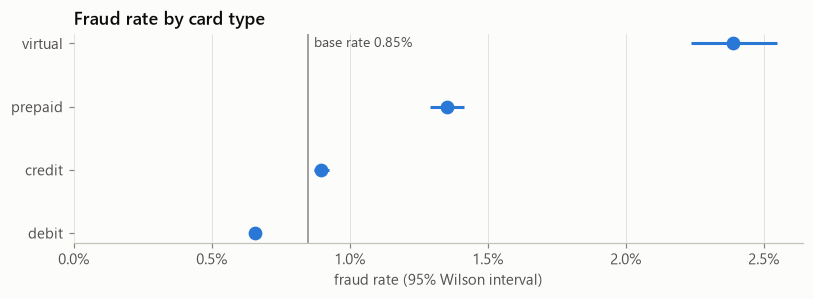

,card_type,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,credit,414477,3720,0.0090,0.0087,0.0093,1.0578
1,debit,760507,5008,0.0066,0.0064,0.0068,0.7761
2,prepaid,132279,1787,0.0135,0.0129,0.0141,1.5922
3,virtual,37487,895,0.0239,0.0224,0.0255,2.8138


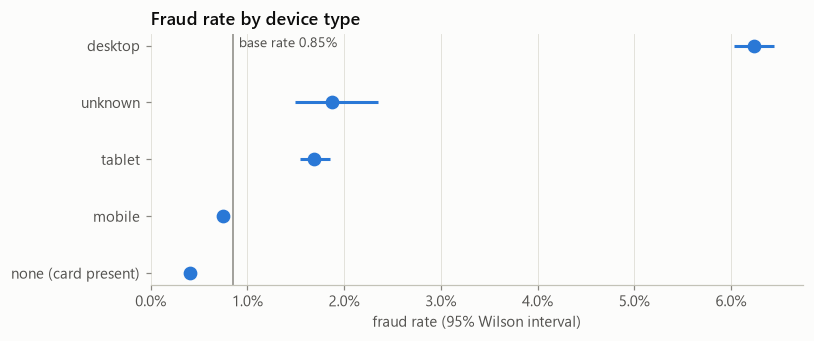

,device_type,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,desktop,54186,3379,0.0624,0.0604,0.0644,7.3495
1,mobile,690886,5164,0.0075,0.0073,0.0077,0.8809
2,none (card present),568774,2337,0.0041,0.0039,0.0043,0.4843
3,tablet,27008,457,0.0169,0.0154,0.0185,1.9943
4,unknown,3896,73,0.0187,0.0149,0.0235,2.2083


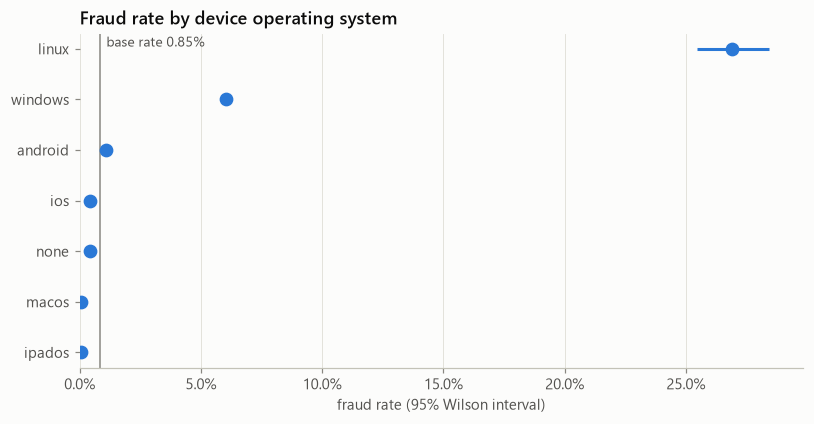

,operating_system,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,android,389976,4250,0.0109,0.0106,0.0112,1.2844
1,ios,311816,1361,0.0044,0.0041,0.0046,0.5144
2,ipados,16102,10,0.0006,0.0003,0.0011,0.0732
3,linux,3442,926,0.2690,0.2545,0.2841,31.7071
4,macos,10254,7,0.0007,0.0003,0.0014,0.0805
5,windows,40490,2446,0.0604,0.0581,0.0628,7.1197
6,none,572670,2410,0.0042,0.0040,0.0044,0.4960


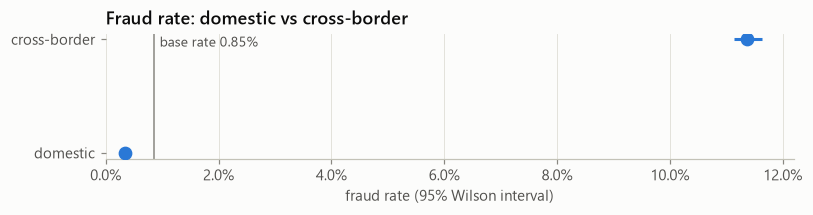

,cross_border,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,cross-border,62145,7069,0.1138,0.1113,0.1163,13.4063
1,domestic,1282605,4341,0.0034,0.0033,0.0035,0.3989


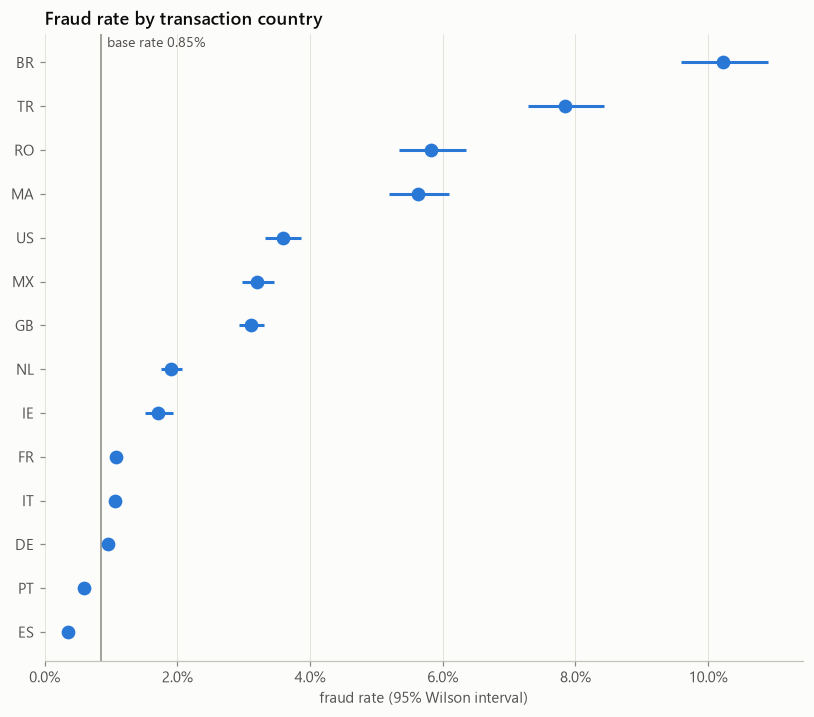

,txn_country,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,BR,8138,832,0.1022,0.0958,0.1090,12.0493
1,DE,57344,544,0.0095,0.0087,0.0103,1.1181
2,ES,902629,3110,0.0034,0.0033,0.0036,0.4061
3,FR,80663,868,0.0108,0.0101,0.0115,1.2682
4,GB,31325,974,0.0311,0.0292,0.0331,3.6646
5,IE,14504,247,0.0170,0.0150,0.0193,2.0071
6,IT,73174,780,0.0107,0.0099,0.0114,1.2563
7,MA,9832,553,0.0562,0.0519,0.0610,6.6289
8,MX,19938,639,0.0320,0.0297,0.0346,3.7772
9,NL,29574,564,0.0191,0.0176,0.0207,2.2476


In [14]:
for column, title in [
    ("payment_method", "Fraud rate by payment method"),
    ("merchant_category", "Fraud rate by merchant category"),
    ("merchant_risk_level", "Fraud rate by merchant risk rating"),
    ("customer_segment", "Fraud rate by customer segment"),
    ("card_type", "Fraud rate by card type"),
    ("device_type", "Fraud rate by device type"),
    ("operating_system", "Fraud rate by device operating system"),
    ("cross_border", "Fraud rate: domestic vs cross-border"),
    ("txn_country", "Fraud rate by transaction country"),
]:
    table = stats.rate_table(df, column)
    fig = plots.plot_rate_by_category(table, column, base_rate, title)
    plots.save(fig, f"rate_by_{column}")
    plt.show()
    display(table.round(4))

### Is the country effect real, or a confounder?

Some transaction countries show fraud rates 10× the base rate. Before calling a country
"risky", split each country by whether the payment is domestic or cross-border for the
customer. If the domestic rates are similar everywhere, the country effect is just the
share of cross-border payments in disguise.

In [15]:
by_country = df.pivot_table(
    index="txn_country",
    columns="cross_border",
    values="is_fraud",
    aggfunc=["size", "mean"],
    observed=True,
)
by_country.columns = [f"{stat}_{kind}" for stat, kind in by_country.columns]
by_country["cross_border_share"] = by_country["size_cross-border"] / (
    by_country["size_cross-border"] + by_country["size_domestic"]
)
display(
    by_country.style.format(
        {
            "size_cross-border": "{:,}",
            "size_domestic": "{:,}",
            "mean_cross-border": "{:.2%}",
            "mean_domestic": "{:.2%}",
            "cross_border_share": "{:.1%}",
        }
    )
)
df["presence"] = np.where(
    df["payment_method"].isin(["chip_pin", "contactless"]), "card present", "card not present"
)
stats.rate_table(df.assign(segment=df["presence"] + " · " + df["cross_border"]), "segment")

,size_cross-border,size_domestic,mean_cross-border,mean_domestic,cross_border_share
txn_country,,,,,
BR,"2,114","6,024",38.36%,0.35%,26.0%
DE,"5,152","52,192",6.64%,0.39%,9.0%
ES,"1,875","900,754",4.00%,0.34%,0.2%
FR,"9,690","70,973",6.52%,0.33%,12.0%
GB,"7,061","24,264",12.55%,0.36%,22.5%
IE,"1,846","12,658",10.08%,0.48%,12.7%
IT,"8,594","64,580",6.31%,0.37%,11.7%
MA,"3,782","6,050",14.23%,0.25%,38.5%
MX,"2,983","16,955",19.11%,0.41%,15.0%


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,card not present · cross-border,39956,5353,0.133972,0.130668,0.137348,15.789601
1,card not present · domestic,736020,3720,0.005054,0.004895,0.005219,0.595675
2,card present · cross-border,22189,1716,0.077336,0.073894,0.080924,9.114555
3,card present · domestic,546585,621,0.001136,0.001050,0.001229,0.133903


## 6. Numeric attributes

Univariate AUC: the probability that a random fraud has a higher value than a random legit
transaction (0.5 = useless on its own; below 0.5 = fraud tends to have LOWER values).

In [16]:
numeric = ["amount_eur", "customer_age", "account_age_days", "card_age_days", "local_hour"]
pd.DataFrame(
    {
        "univariate_auc": [stats.univariate_auc(df[c], df["is_fraud"]) for c in numeric],
        "median_legit": [df.loc[~df["is_fraud"], c].median() for c in numeric],
        "median_fraud": [df.loc[df["is_fraud"], c].median() for c in numeric],
    },
    index=numeric,
).round(3)

,univariate_auc,median_legit,median_fraud
amount_eur,0.703,40.780,122.800
customer_age,0.491,43.000,43.000
account_age_days,0.507,1425.648,1462.244
card_age_days,0.473,1327.874,1203.199
local_hour,0.399,15.000,13.000


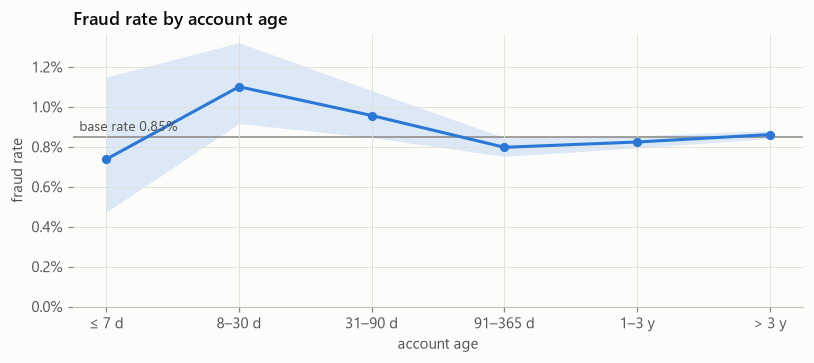

,account_age_bucket,transactions,frauds,fraud_rate,ci_low,ci_high,lift
0,≤ 7 d,2576,19,0.007376,0.004727,0.011492,0.869288
1,8–30 d,10267,113,0.011006,0.009163,0.013215,1.297152
2,31–90 d,26657,255,0.009566,0.008466,0.010807,1.127418
3,91–365 d,138322,1103,0.007974,0.007519,0.008457,0.939810
4,1–3 y,346437,2854,0.008238,0.007943,0.008545,0.970925
5,> 3 y,820491,7066,0.008612,0.008414,0.008814,1.014976


In [17]:
age_bins = [-1, 7, 30, 90, 365, 3 * 365, 100 * 365]
age_labels = ["≤ 7 d", "8–30 d", "31–90 d", "91–365 d", "1–3 y", "> 3 y"]
df["account_age_bucket"] = pd.cut(df["account_age_days"], age_bins, labels=age_labels)
by_account_age = stats.rate_table(df, "account_age_bucket")
fig = plots.plot_rate_over(
    by_account_age, "account_age_bucket", base_rate, "Fraud rate by account age", "account age"
)
plots.save(fig, "rate_by_account_age")
plt.show()
display(by_account_age)

## 7. Interactions (preview for feature design)

Fraud rate by channel and amount band. A model that only adds effects (logistic regression
without interaction terms) cannot represent a pattern that exists in one channel only.

In [18]:
df["amount_band"] = pd.cut(
    amount, [0, 5, 20, 100, 500, np.inf], labels=["< 5", "5–20", "20–100", "100–500", "≥ 500"]
)
pivot = df.pivot_table(
    index="payment_method",
    columns="amount_band",
    values="is_fraud",
    aggfunc="mean",
    observed=True,
)
counts = df.pivot_table(
    index="payment_method",
    columns="amount_band",
    values="is_fraud",
    aggfunc="size",
    observed=True,
)
display(pivot.style.format("{:.2%}").set_caption("fraud rate"))
display(counts.style.format("{:,}").set_caption("transactions"))

amount_band,< 5,5–20,20–100,100–500,≥ 500
payment_method,,,,,
chip_pin,0.02%,0.11%,0.48%,2.10%,1.10%
contactless,0.00%,0.06%,0.21%,0.74%,0.31%
ecommerce,2.86%,0.17%,0.85%,2.49%,5.09%
mobile_wallet,0.04%,0.02%,0.07%,0.94%,5.75%


amount_band,< 5,5–20,20–100,100–500,≥ 500
payment_method,,,,,
chip_pin,"4,349","47,881","138,047","33,805","4,525"
contactless,"6,498","71,509","205,666","49,621","6,873"
ecommerce,"47,073","125,111","249,017","121,592","28,152"
mobile_wallet,"12,358","44,489","100,509","39,258","8,417"


## 8. Associations between attributes

Strongly associated predictors carry overlapping information (and make linear-model
coefficients unstable). Cramér's V for categorical pairs, Spearman for numeric pairs.

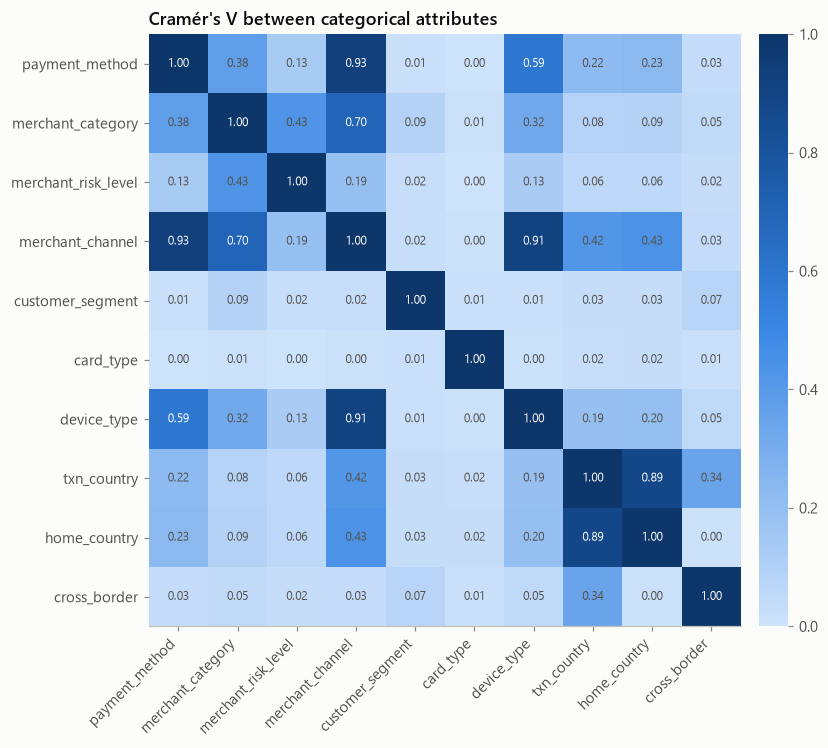

In [19]:
pair_columns = [c for c in categorical if c != "operating_system"]
cramer = pd.DataFrame(index=pair_columns, columns=pair_columns, dtype=float)
for i, a in enumerate(pair_columns):
    for b in pair_columns[i:]:
        value = 1.0 if a == b else stats.cramers_v(df[a], df[b])
        cramer.loc[a, b] = cramer.loc[b, a] = value
fig = plots.plot_heatmap(cramer, "Cramér's V between categorical attributes")
plots.save(fig, "cramers_v_matrix")
plt.show()

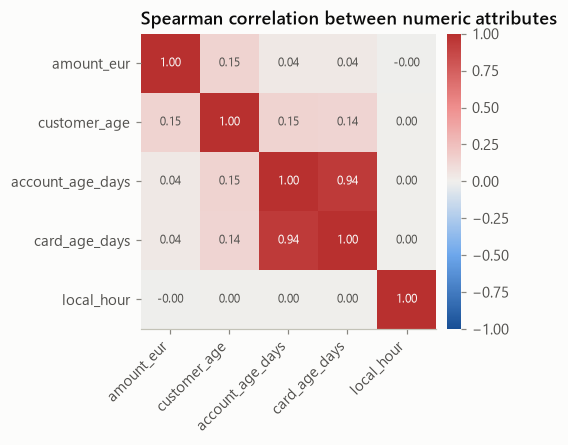

,amount_eur,customer_age,account_age_days,card_age_days,local_hour
amount_eur,1.000,0.147,0.039,0.036,-0.003
customer_age,0.147,1.000,0.148,0.139,0.001
account_age_days,0.039,0.148,1.000,0.944,0.001
card_age_days,0.036,0.139,0.944,1.000,0.001
local_hour,-0.003,0.001,0.001,0.001,1.000


In [20]:
spearman = df[numeric].corr(method="spearman")
fig = plots.plot_heatmap(
    spearman, "Spearman correlation between numeric attributes", diverging=True
)
plots.save(fig, "spearman_matrix")
plt.show()
spearman.round(3)

## 9. Findings

The full write-up, with every number from this run and the caveats about which signals
are artificial, is in [`reports/eda/eda_findings.md`](../reports/eda/eda_findings.md).
In short:

- Base rate 0.848%: accuracy is meaningless; precision collapses at modest false positive
  rates; review capacity will drive the decision policy.
- Only 42.9% of fraud labels exist two weeks after the transaction.
- Amount is extremely skewed and U-shaped (micro-charges and large tickets); outliers are
  signal.
- Cross-border is the strongest attribute; the apparent country effect is a confounder of it.
- Night hours, merchant category, device type and card type matter; weekday, customer age
  and account age barely do on their own.
- Several strong signals (operating system, night hours) are strong *because of how the
  simulator was built*.